# Optimización multiobjetivo: revisión de NSGA-II
Se conserva íntegra la implementación y el notebook `06.2_ngsaii_implementation.ipynb` del compañero. Aquí se revisan el frente y el costo guardados, sin volver a ejecutar una búsqueda de horas.

Objetivos de búsqueda: maximizar recurso entregado, minimizar distancia media y minimizar presión de competencia. Las réplicas 1–30 se usaron para buscar y 31–100 para evaluar. Estas últimas ya fueron examinadas por los autores: el análisis actual es descriptivo, no confirmatorio pre-registrado.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config/project2/base.yaml').exists())
sys.path.insert(0, str(ROOT / 'src'))
from bee_sim.analysis.project2_comparison import build_comparison
data = build_comparison(ROOT)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


In [2]:
display(pd.Series(data['metadata'], name='valor').to_frame())
history = pd.read_csv(ROOT / 'results/project2/nsga2/history.csv')
display(history.tail())

,valor
selected_nsga_solution,pareto_047
selection_rule,Equal-weight normalized distance to ideal usin...
holdout_already_inspected,True
interpretation,"descriptive synthetic comparison, not ecologic..."
original_front_solutions,49
physical_front_installations,32
candidate_ids,375
unique_candidate_coordinates,351
search_simulations,75240
search_recorded_hours,6.382957


,generation,front_size,archive_size,infeasible,new_simulations,elapsed_s,best_total_resource_obtained,mean_total_resource_obtained,best_mean_distance_m,mean_mean_distance_m,best_competition_pressure,mean_competition_pressure
46,46,41,41,0,1320,367.295239,969.390309,946.025971,1232.413772,1389.436320,0.0,0.000361
47,47,43,43,0,1410,436.629018,969.390309,945.174379,1232.413772,1383.804345,0.0,0.000371
48,48,45,45,0,1500,398.310021,969.390309,945.384003,1232.413772,1383.143135,0.0,0.000368
49,49,47,47,0,1440,378.903439,969.390309,949.691101,1232.413772,1386.432341,0.0,0.000348
50,50,49,49,0,1380,364.255996,969.390309,949.184510,1232.413772,1380.253510,0.0,0.000335


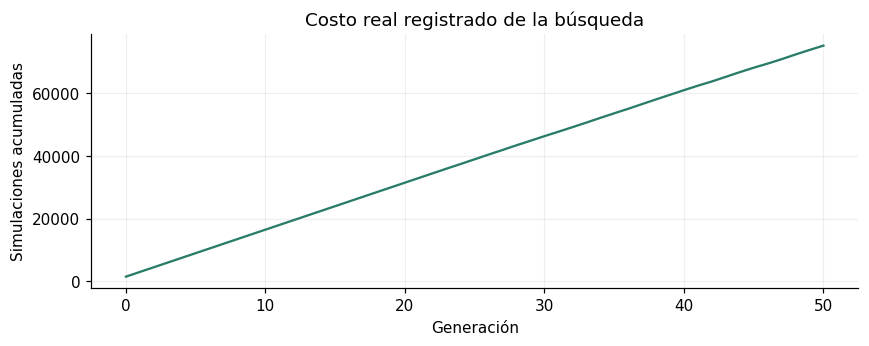

In [3]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(history.generation, history.new_simulations.cumsum(), color='#287c68')
ax.set(xlabel='Generación', ylabel='Simulaciones acumuladas', title='Costo real registrado de la búsqueda')
ax.grid(alpha=.2)
plt.show()

## Depuración y presupuesto
La búsqueda guardada evaluó 75 240 simulaciones y registró aproximadamente 6,38 horas. El frente contiene 49 soluciones por ID pero 32 conjuntos distintos de coordenadas: hay 375 IDs candidatos y 351 coordenadas únicas. Se preservan todos los resultados; la visualización evita contar alternativas físicamente repetidas como distintas.

El motor acelerado evita deserializar la configuración en cada evento y reemplaza recorridos de contadores por operaciones NumPy. La corrida de referencia produjo exactamente las mismas métricas y tablas de eventos; el ensayo perfilado pasó de 2,52 a 0,50 s. Es un ensayo individual, no una garantía de tiempo para toda la búsqueda.

La caché nueva incluye datos, motor y configuración, completa seeds faltantes y recupera logs interrumpidos conservando copia. El presupuesto predeterminado es de 3 000 simulaciones nuevas por invocación. Las salidas nuevas van a `nsga2_fast`, sin sobrescribir el frente histórico.

Inspeccionar antes de ejecutar desde la raíz:
```powershell
$env:PYTHONPATH='src'
python -m bee_sim.project2.strategies.nsga2 search --dry-run
```
Un nuevo motor requiere una nueva búsqueda/cohorte; no se debe reutilizar el checkpoint histórico con otra identidad.

In [4]:
display(data['nsga_installations'][['solution_id','total_resource_obtained','mean_distance_m','competition_pressure','physical_duplicate']])

,solution_id,total_resource_obtained,mean_distance_m,competition_pressure,physical_duplicate
0,pareto_001,960.901043,1426.070620,0.000238,False
1,pareto_002,965.712358,1428.270126,0.000952,False
2,pareto_003,965.712358,1428.270126,0.000952,True
3,pareto_004,953.127817,1393.708194,0.000238,False
4,pareto_005,950.674071,1344.550905,0.000926,False
5,pareto_006,950.674071,1344.550905,0.000926,True
6,pareto_007,942.434934,1314.310175,0.000874,False
7,pareto_008,942.434934,1314.310175,0.000874,True
8,pareto_009,941.598171,1354.312451,0.000238,False
9,pareto_010,958.629941,1415.347464,0.000237,False


## Pendiente
Sensibilidad a alpha, beta, regeneración, demanda y recursos; decidir prohibición de colocalización física; medir convergencia con varios optimizer seeds; reoptimizar si se cambia el escenario. No interpretar un frente sintético como recomendación de instalar colmenas reales.